## The low-$k$ maximum of shear-flow tearing near $\alpha=1$

**Question.** The rung-2 campaign (`tearing-kmax.ipynb`, sections 3-4) found a second, low-$k$ maximum of $\gamma(k)$ for $\Psi_0=\mathrm{sech}^2x$, $\Phi_0=\alpha\Psi_0$ that takes over the global maximum at $\alpha\gtrsim0.95$ and low $S$. This notebook identifies it and maps where it dominates.

**Setup** (as rungs 1b-ref/1b/2): `dims=2`, `hyper=1`, $a=v_{Ay}=1$, $S=1/\eta$, $\nu=0$ unless a Pm is given, ky block, fp64. Wavenumber and the $(\nu,\eta)$ pair enter through `overrides={"Ly": 2π/k, "diss": (ν, η)}`. Data: `tearing_lowk_run.py` (one cache file per solve under `examples/data/tearing-lowk/`); this notebook only reads. Gate: `tests/test_tearing_lowk.py`.

**Identification (details and evidence below).** The low-$k$ maximum is not a box artifact and not a second, separate instability. It is consistent with being the part of the real tearing branch that survives at $\alpha=1$, where the shear-modified tearing of the paper (Mallet et al., JPP 2025) vanishes. (The paper, which sets $\nu=0$, states that tearing is completely stabilised as the flow becomes Alfvénic; that holds for its high-$k$ branch, but the $\nu=0$ eigenproblem keeps this weaker resistive mode at $\alpha=1$ at finite $S$.) At $\alpha=1$ exactly (the Alfvénic state, $Z^-=\Phi_0-\Psi_0=0$) the linear problem has **no growing eigenmode when $\nu=\eta>0$** (a two-line Elsasser energy argument, section 4: it bounds $\|\delta z^-\|$, not the total energy), but with $\nu=0$ a real, resistive, $\Delta'$-driven mode remains: it is cut off at the ideal marginal point $ka=\sqrt5$ exactly like tearing, $\gamma^*\propto S^{-0.66}$, $k^*\propto S^{-0.17}$. Its growth is fed by the resistive asymmetry: resistivity diffuses $b$ but not $u$, which converts $\delta z^+$ into $\delta z^-$ (the cross-dissipation term $X^-$), and the shear of $Z^+$ converts it back. For $\alpha>1$ the same real branch continues smoothly into the ideal Kelvin-Helmholtz instability ($\gamma$ independent of $S$). For $\alpha<1$ it is suppressed only weakly by $1-\alpha^2$, while the paper's high-$k$ tearing maximum falls like $(1-\alpha^2)^{0.59}$, so it wins for $\alpha$ close enough to 1. The window where it wins closes roughly as $1-\alpha_c^2\approx16\,S^{-0.75}$ (fit over $S=5\times10^3$-$10^5$ only, local slope still drifting; box-corrected in section 7), and it needs $\mathrm{Pm}\ll1$: at $\mathrm{Pm}=1$ the low-$k$ maximum is gone at $S=10^4$, $\alpha=0.995$.

In [1]:
# fp64 before taranis/jax import; this notebook only READS the cache of tearing_lowk_run.py
import os
os.environ["TARANIS_PRECISION"] = "64"
os.environ.setdefault("TARANIS_LK_PROFILE", "full")
import time
import numpy as np
import matplotlib.pyplot as plt
import tearing_lowk_run as L
R = L.R

t0 = time.time()
BOX = L.box_results()
JL = L.julia_results()
SCAN = L.scan_results()
REF = L.ref_results()
CUT = L.cutoff_results()
A1 = L.alpha1_results()
PM = L.pm_results()
BND = L.boundary_results()
BNDN = L.boundary_newton_results()
BOTH = {S: [x for x in r["rows"] if x["lo"] is not None and x["hi"] is not None] for S, r in BND.items()}
BCHK = {S: L.boundary_check(r) for S, r in BND.items() if BOTH[S]}
BBOX = {S: L.boundary_box_check(r) for S, r in BND.items() if BOTH[S]}   # added in review
ST = L.struct_results()
PMS = L.pmscan_results()
print(f"profile {L.PROFILE}: {sum(len(v) for v in BOX.values())} box solves, {len(JL)} Julia points, "
      f"{sum(len(v) for v in SCAN.values())} scan spectra, {len(A1['kmax'])} alpha = 1 maxima, "
      f"{len(A1['gs'])} gamma(S) points, {len(PM)} Pm points, {len(BND)} alpha_c values, "
      f"{len(ST)} structure maxima; read in {time.time() - t0:.1f} s")
SEQ = plt.get_cmap("viridis")

field variables are using 64bit precision.
profile full: 25 box solves, 4 Julia points, 396 scan spectra, 5 alpha = 1 maxima, 20 gamma(S) points, 28 Pm points, 7 alpha_c values, 5 structure maxima; read in 2.7 s


### 1. Box and grid: not an artifact

The rung-2 $k_{max}$ box is $L_x=20/k_{th}(S)$, which at the low-$k$ point $S=10^4$, $ka=0.179$ is only $kL_x=7.7$. Here $\gamma$ is re-solved at fixed $(S,\alpha,k)$ with $L_x\times0.5,1,2(,4)$ at fixed $dx$ and with $n_x\times0.5,1,2$ at the rung-2 box. The fourth point (high-$k$ tearing, $S=10^4$, $\alpha=0.99$, $ka=0.713$) is the control. Then the same points with Alfred's Julia eigencode (`tests/reference/shear_tearing_eigen.jl`), an independent discretization (nonuniform grid, three joint $(dx_{min},\epsilon)$ levels, 2nd-order Richardson) with an open Robin outer boundary at $x_{lim}$ instead of periodic images.

In [2]:
# (a) the taranis box/grid study at fixed (S, alpha, k): Lx factors at fixed dx, nx factors at the
# rung-2 box. (b) Julia eigencode (open Robin boundary at xlim, nonuniform grid): three joint
# (dxmin, eps) levels per xlim, Richardson at 2nd order from the last two
print(f"{'S':>7s} {'alpha':>6s} {'ka':>6s} | {'factor':>9s} {'Lx':>8s} {'nx':>6s} {'gamma':>18s} {'rel. to largest box':>20s} {'q_S':>9s}")
for pt, rows in BOX.items():
    big = rows[max((k for k in rows if k[0] == "Lx"), key=lambda k: k[1])]
    gref = L.growth(big)
    for key in sorted(rows):
        r = rows[key]
        print(f"{pt[0]:7.0e} {pt[1]:6g} {pt[2]:6g} | {key[0]:>3s} x{key[1]:<4g} {float(r['Lx']):8.3f} "
              f"{int(r['nx']):6d} {L.growth(r):18.12e} {L.growth(r)/gref - 1:+20.2e} {L.s_exponent(r):+9.5f}")
    print()
print("Julia eigencode (Robin boundary at xlim):")
for pt, t in JL.items():
    big = BOX[pt][max((k for k in BOX[pt] if k[0] == "Lx"), key=lambda k: k[1])]
    for xl, gs in t.items():
        g = [z.real for z in gs]
        rich = g[-1] + (g[-1] - g[-2])/3
        print(f"  {pt}  xlim = {xl:4.0f}: levels {g[0]:.9e} {g[1]:.9e} {g[2]:.9e}  Richardson {rich:.9e}  "
              f"vs taranis (largest box) {rich/L.growth(big) - 1:+.1e}")

      S  alpha     ka |    factor       Lx     nx              gamma  rel. to largest box       q_S
  1e+04  0.995  0.179 |  Lx x0.5    21.513   2048 3.457956333060e-03            +2.41e-02  -0.99518
  1e+04  0.995  0.179 |  Lx x1      43.026   4096 3.378198352291e-03            +5.24e-04  -0.97750
  1e+04  0.995  0.179 |  Lx x2      86.052   8192 3.376429074690e-03            +2.37e-07  -0.97711
  1e+04  0.995  0.179 |  Lx x4     172.103  16384 3.376428273539e-03            +0.00e+00  -0.97711
  1e+04  0.995  0.179 |  nx x0.5    43.026   2048 3.378198352579e-03            +5.24e-04  -0.97750
  1e+04  0.995  0.179 |  nx x1      43.026   4096 3.378198352291e-03            +5.24e-04  -0.97750
  1e+04  0.995  0.179 |  nx x2      43.026   8192 3.378198352121e-03            +5.24e-04  -0.97750

  1e+03  0.995   0.36 |  Lx x0.5    15.608   1024 2.290705305605e-02            +7.21e-03  -0.69643
  1e+03  0.995   0.36 |  Lx x1      31.216   2048 2.274369374542e-02            +2.67e-05  -0.69634

**Result (section 1).** The low-$k$ growth rate is a converged property of the infinite-domain problem. At $S=10^4$, $\alpha=0.995$, $ka=0.179$, halving or doubling $n_x$ changes $\gamma$ by $<10^{-10}$. The box error at the rung-2 box is $+5.24\times10^{-4}$: doubling $L_x$ gives $3.376429\times10^{-3}$, and doubling again changes that by $2.4\times10^{-7}$. Halving the box raises $\gamma$ by $2.4\%$, so the error falls roughly like $e^{-kL_x}$, the image coupling of the outer solution. The Julia eigencode, with an open boundary at $x_{lim}=40$, gives $3.376433\times10^{-3}$, which is $1.3\times10^{-6}$ from the largest periodic box. The same holds at $\alpha=1$ ($S=10^4$, $ka=0.18$: box error $7.8\times10^{-4}$ at the rung-2 box, Julia within $8\times10^{-7}$ of the doubled box) and at $S=10^3$ ($2.7\times10^{-5}$, Julia within $3\times10^{-8}$). The high-$k$ control is box-independent to $2\times10^{-11}$ and agrees with Julia to $10^{-7}$. So at $S=10^4$ the rung-2 $k_{max}$ values of the low-$k$ branch carry a box error of a few $10^{-4}$. The error grows with $S$, because $k^*_{low}$ falls while the rung-2 box ($L_x=20/k_{th}$) grows only like $S^{1/7}$: $k^*_{low}L_x=7.6$ at $S=10^4$ but $5.0$ at $5\times10^4$ and $4.2$ at $10^5$, where the low-$k$ $\gamma$ is $0.5\%$ and $1.3\%$ too high (section 7's box check). That biases $\alpha_c$ at the largest $S$.

### 2. $\gamma(k)$ through $\alpha=1$

The top real eigenvalue of the dense block on a coarse grid ($n_x\le1024$, rung-2 box; grid-converged to $\le10^{-9}$ at the maxima: section 1 at $S=10^3$, section 7's grid checks at $S=10^4$) on 22 $ka$ from 0.05 to 1.6, for $\alpha$ from 0.9 through 1 to 1.05. Dots: grid local maxima.

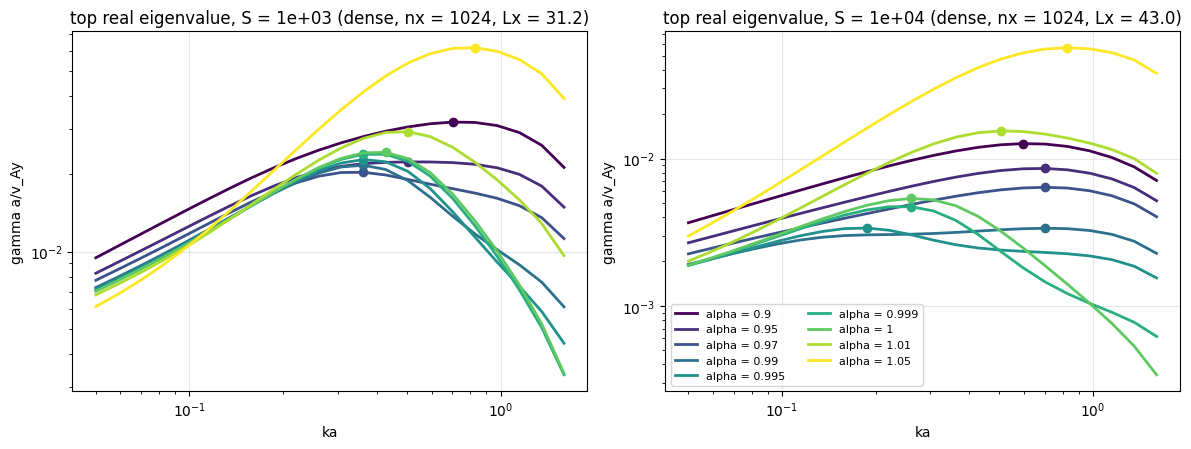

grid local maxima (ka, gamma):
  S = 1e+03 alpha = 0.9   : (0.7011, 3.1783e-02)   [max |Im|/|lambda| of the top over ka: 1.7e-12]
  S = 1e+03 alpha = 0.95  : (0.504, 2.2279e-02)   [max |Im|/|lambda| of the top over ka: 7.3e-12]
  S = 1e+03 alpha = 0.97  : (0.3623, 2.0315e-02)   [max |Im|/|lambda| of the top over ka: 5.1e-12]
  S = 1e+03 alpha = 0.99  : (0.3623, 2.1625e-02)   [max |Im|/|lambda| of the top over ka: 4.7e-11]
  S = 1e+03 alpha = 0.995 : (0.3623, 2.2752e-02)   [max |Im|/|lambda| of the top over ka: 7.4e-11]
  S = 1e+03 alpha = 0.999 : (0.3623, 2.3858e-02)   [max |Im|/|lambda| of the top over ka: 2.7e-11]
  S = 1e+03 alpha = 1     : (0.4273, 2.4260e-02)   [max |Im|/|lambda| of the top over ka: 7.0e-12]
  S = 1e+03 alpha = 1.01  : (0.504, 2.9182e-02)   [max |Im|/|lambda| of the top over ka: 2.2e-11]
  S = 1e+03 alpha = 1.05  : (0.8268, 6.1731e-02)   [max |Im|/|lambda| of the top over ka: 3.6e-12]
  S = 1e+04 alpha = 0.9   : (0.5944, 1.2633e-02)   [max |Im|/|lambda| of the top

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), sharey=False)
for ax, S in zip(axs, L.S_SCAN):
    als = [al for al in L.ALPHA_SCAN if SCAN.get((S, al))]
    for i, al in enumerate(als):
        rows = SCAN[(S, al)]
        kas = sorted(rows)
        g = [L.top_real(rows[k]["values"]) for k in kas]
        ax.plot(kas, g, "-", lw=2, color=SEQ(i/max(1, len(als) - 1)), label=f"alpha = {al:g}")
        for (km, gm) in L.scan_maxima(rows):
            ax.plot(km, gm, "o", ms=6, color=SEQ(i/max(1, len(als) - 1)))
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("ka"); ax.set_ylabel("gamma a/v_Ay")
    ax.set_title(f"top real eigenvalue, S = {S:.0e} (dense, nx = {min(L.NX_DENSE, L.box(S)[1])}, Lx = {L.box(S)[0]:.1f})")
    ax.grid(alpha=0.3)
axs[1].legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()
print("grid local maxima (ka, gamma):")
for (S, al), rows in SCAN.items():
    if rows:
        print(f"  S = {S:.0e} alpha = {al:<6g}: " + "  ".join(f"({k:.4g}, {g:.4e})" for k, g in L.scan_maxima(rows))
              + f"   [max |Im|/|lambda| of the top over ka: "
              f"{max(abs(complex(r['values'][0]).imag)/abs(complex(r['values'][0])) for r in rows.values()):.1e}]")

**Result (section 2).** The top eigenvalue is real at every point ($|\mathrm{Im}\,\lambda|/|\lambda|\le8\times10^{-11}$), including $\alpha>1$, and the curves deform continuously across $\alpha=1$, consistent with a single real branch (continuity on this $\alpha$ grid, not a continuation proof). At $S=10^3$ the maximum migrates from $ka=0.70$ ($\alpha=0.9$) through a flat top ($\alpha=0.95$, maximum at 0.50) to $ka=0.36$ ($\alpha\ge0.97$). Past $\alpha=1$ it moves back out to 0.50 ($\alpha=1.01$) and 0.83 ($\alpha=1.05$) as $\gamma$ grows. At $S=10^4$ the global maximum jumps from $ka=0.70$ ($\alpha=0.99$, $3.363\times10^{-3}$) to $0.19$ ($\alpha=0.995$, $3.373\times10^{-3}$). At $\alpha=1$ it sits at 0.26 with $\gamma=5.357\times10^{-3}$, and at $\alpha=1.01$ at 0.50 with $1.54\times10^{-2}$. Near $\alpha=1$ the low-$k$ growth rate *rises* with $\alpha$ and is finite at $\alpha=1$, while the high-$k$ hump of the paper's shear-modified tearing ($\gamma\propto(1-\alpha^2)^{4/7}$) disappears. The scan's grid-convergence claim at $S=10^4$ ($n_x=1024$, a quarter of the rung-2 $n_x$) rests on section 7's grid checks ($\le2.5\times10^{-10}$ at nx 1024 vs 4096), not on section 1.

### 3. The ideal marginal point: is it $\Delta'$-driven?

For $\mathrm{sech}^2$, $\Delta'a=2(5-k^2a^2)(k^2a^2+3)/(k^2a^2\sqrt{k^2a^2+4})$ changes sign at $ka=\sqrt5=2.23607$. A mode driven by the flow shear alone would not know about $\Delta'$.

In [4]:
# gamma across the ideal marginal point ka = sqrt 5 (Delta' = 0), S = CUTOFF_S, rung-2 box, dense
print(f"S = {L.CUTOFF_S:.0e}, sqrt 5 = {np.sqrt(5):.5f}")
print(f"{'ka':>6s} " + " ".join(f"{'alpha=' + format(al, 'g'):>14s}" for al in L.CUTOFF_ALPHA))
for ka in L.CUTOFF_KA:
    print(f"{ka:6g} " + " ".join(f"{complex(CUT[(al, ka)]['values'][0]).real:+14.4e}" for al in L.CUTOFF_ALPHA))

S = 1e+03, sqrt 5 = 2.23607
    ka        alpha=0    alpha=0.995        alpha=1
   1.6    +3.4490e-02    +4.4183e-03    +3.3707e-03
     2    +1.1683e-02    +1.9632e-03    +1.1022e-03
   2.2    +3.9052e-04    +3.6145e-04    +1.6149e-04
  2.23    +7.2993e-06    +6.3534e-05    +2.7023e-05
  2.24    +6.8576e-16    +6.5772e-14    +8.2357e-14
   2.3    +8.5118e-16    +6.6291e-14    +8.3493e-14
   2.6    +6.9699e-16    +7.1654e-14    +8.6654e-14


**Result (section 3).** At $\alpha=1$ the instability ends at $ka=\sqrt5$ exactly as the static tearing mode does: $\gamma=2.70\times10^{-5}$ at $ka=2.23$ and nothing above round-off at $2.24$, $2.3$, $2.6$. The same holds at $\alpha=0.995$. The low-$k$/$\alpha=1$ mode is therefore a tearing mode in the sense that matters: it is released only where $\Delta'>0$. It is not a flow-driven (Kelvin-Helmholtz-type) mode at $\alpha\le1$.

### 4. $\alpha=1$ and beyond

**Why $\alpha=1$ is special.** The code's RMHD (`physics/rmhd.py`: $\partial_t\omega=\{\psi,j\}-\{\phi,\omega\}$, $\partial_t\psi=-\{\phi,\psi\}$, with $u=\hat z\times\nabla\phi$, $b=\hat z\times\nabla\psi$, $\omega=\nabla^2\phi$, $j=\nabla^2\psi$) is 2D incompressible MHD, so with $\delta z^\pm=\delta u\pm\delta b=\hat z\times\nabla(\phi\pm\psi)$ and the background $Z^\pm_y=(\alpha\pm1)B$ the linearized equations are
$$\partial_t\delta z^\pm+(Z^\mp\!\cdot\nabla)\delta z^\pm+(\delta z^\mp\!\cdot\nabla)Z^\pm=-\nabla\delta p+\tfrac{\nu+\eta}2\nabla^2\delta z^\pm+\tfrac{\nu-\eta}2\nabla^2\delta z^\mp.$$
**Statement.** *Hypotheses:* $Z^-\equiv0$ exactly ($\Phi_0=\Psi_0$, any profile), $\nu=\eta>0$ (the same Laplacian on both fields), the linearized (frozen-equilibrium) problem. *Conclusion:* no eigenvalue has $\mathrm{Re}\,\lambda\ge0$, for any profile, $k$ or $S$. *Proof:* with $Z^-=0$ the $\delta z^-$ equation keeps only advection by the divergence-free $Z^+$ (no work on $\|\delta z^-\|^2$), the pressure (none on a solenoidal field) and, at $\nu=\eta$, no cross term, so $d\|\delta z^-\|^2/dt=-(\nu+\eta)\|\nabla\delta z^-\|^2<0$ for $\delta z^-\ne0$: an eigenmode with $\delta z^-\ne0$ has $\mathrm{Re}\,\lambda<0$. If $\delta z^-\equiv0$, the only coupling of $\delta z^+$, $(\delta z^-\!\cdot\nabla)Z^+$, vanishes and $\delta z^+$ diffuses: $\mathrm{Re}\,\lambda<0$ again. *What it does not say:* only $\|\delta z^-\|$ is monotone. $\|\delta z^+\|$, and with it the total energy, is driven by $(\delta z^-\!\cdot\nabla)Z^+$ and can grow transiently (non-normal amplification); the statement is about modal (exponential) growth. Ideally ($\nu=\eta=0$) $\|\delta z^-\|$ is conserved and the same argument excludes $\mathrm{Re}\,\lambda>0$. With $\nu\ne\eta$ the cross term $\tfrac{\nu-\eta}2\nabla^2\delta z^+$ feeds $\delta z^-$ from $\delta z^+$ and the argument fails: a growing mode at $\alpha=1$ needs $\nu\ne\eta$, and with $\nu=0$ it is resistive. Gated in `test_tearing_lowk.py` (no growing dense eigenvalue at $\nu=\eta$; $T^-=X^-=0$ exactly for any vector), and section 5 shows it ($-7.1\times10^{-6}$ at $\mathrm{Pm}=1$).

Below: $k_{max}$ at $\alpha=1$ by Newton on $\partial_k\gamma=0$ (sensitivities through the overrides seam), and $\gamma(S)$ at fixed $ka=0.2$ for $\alpha=0.995$, $1$, $1.02$, $1.1$.

alpha = 1 (Z- = 0): the maximum over k by Newton (rung-2 box), nu = 0
      S          k*         gamma*  q_S at k*  secant dln g*/dlnS  secant dln k*/dlnS    psi0      E-/E   width
  1e+03   0.3993491 2.43760246e-02    -0.6479                                          0.0544  6.08e-04  0.3899
  3e+03   0.3296546 1.18785069e-02    -0.6589             -0.6543             -0.1746  0.0326  1.60e-04  0.3557
  1e+04   0.2672248 5.36066823e-03    -0.6618             -0.6608             -0.1744  0.0184  3.70e-05  0.3161
  3e+04   0.2206641 2.59143814e-03    -0.6611             -0.6616             -0.1743  0.0108  9.79e-06  0.2796
  1e+05   0.1790059 1.17013242e-03    -0.6595             -0.6604             -0.1738  0.0060  2.29e-06  0.2411

gamma(S) at fixed ka = 0.2 (box Lx = 15/k = 75, nx = rung-1a rule/4 >= 2048; 2nx checks at S = 3e4, 1e5: max |change| = 1.1e-10)
  alpha = 0.995 : S=1e+03: 1.7633e-02 (q_S -0.559)  S=3e+03: 9.0810e-03 (q_S -0.668)  S=1e+04: 3.3435e-03 (q_S -1.051)  S=3e+04:

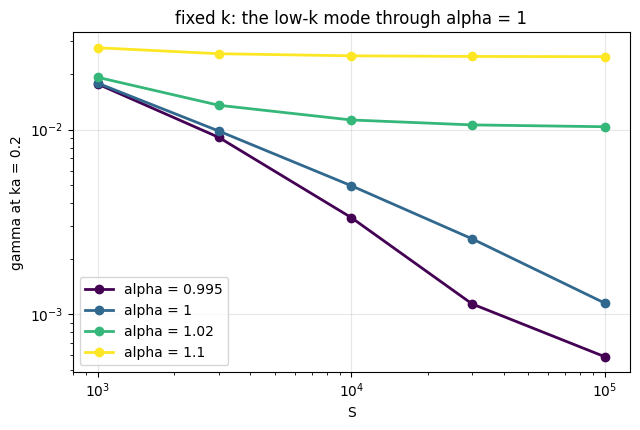

In [5]:
print("alpha = 1 (Z- = 0): the maximum over k by Newton (rung-2 box), nu = 0")
print(f"{'S':>7s} {'k*':>11s} {'gamma*':>14s} {'q_S at k*':>10s} {'secant dln g*/dlnS':>19s} {'secant dln k*/dlnS':>19s} {'psi0':>7s} {'E-/E':>9s} {'width':>7s}")
prev = None
for S, r in A1["kmax"].items():
    rec = r["rec"]
    sl = ("", "")
    if prev is not None:
        dl = np.log(S/prev[0])
        sl = (f"{np.log(r['gmax']/prev[2])/dl:+19.4f}", f"{np.log(r['kmax']/prev[1])/dl:+19.4f}")
    print(f"{S:7.0e} {r['kmax']:11.7f} {r['gmax']:14.8e} {L.s_exponent(rec):+10.4f} {sl[0]:>19s} {sl[1]:>19s} "
          f"{float(rec['psi0']):7.4f} {float(rec['em_frac']):9.2e} {float(rec['width']):7.4f}")
    prev = (S, r["kmax"], r["gmax"])
print(f"\ngamma(S) at fixed ka = {L.KA_GS} (box Lx = 15/k = {L.gs_box(1e3)[0]:.0f}, nx = rung-1a rule/4 >= 2048; "
      f"2nx checks at S = 3e4, 1e5: max |change| = "
      f"{max(abs(L.growth(r)/L.growth(A1['gs'][key]) - 1) for key, r in A1['gs_check'].items()):.1e})")
fig, ax = plt.subplots(figsize=(6.5, 4.4))
for i, al in enumerate(L.ALPHA_GS):
    pts = sorted((S, r) for (a, S), r in A1["gs"].items() if a == al)
    if not pts:
        continue
    Ss = [S for S, _ in pts]; g = [L.growth(r) for _, r in pts]
    ax.loglog(Ss, g, "o-", lw=2, ms=6, color=SEQ(i/max(1, len(L.ALPHA_GS) - 1)), label=f"alpha = {al:g}")
    print(f"  alpha = {al:<6g}: " + "  ".join(f"S={S:.0e}: {L.growth(r):.4e} (q_S {L.s_exponent(r):+.3f})" for S, r in pts))
ax.set_xlabel("S"); ax.set_ylabel(f"gamma at ka = {L.KA_GS}"); ax.grid(alpha=0.3); ax.legend()
ax.set_title("fixed k: the low-k mode through alpha = 1"); plt.tight_layout(); plt.show()

**Result (section 4).** At $\alpha=1$ the maximum is a resistive mode with clean power laws over two decades: $\gamma^*=2.438\times10^{-2}\to1.170\times10^{-3}$ and $k^*=0.399\to0.179$ for $S=10^3\to10^5$. The local $d\ln\gamma^*/d\ln S$ (one sensitivity, envelope theorem) is $-0.648$, $-0.659$, $-0.662$, $-0.661$, $-0.660$, and the secant slopes are $-0.654$ to $-0.662$ ($\gamma^*$) and $-0.174$ ($k^*$). These are neither the static $-3/7$, $-1/7$ nor the paper's shear-modified values, which give $\gamma\to0$ at $\alpha=1$. The reconnected flux at the X-point is small and falls with $S$: $|\psi(0)|/\max|\psi|=0.054\to0.0060$. The perturbation is almost pure $\delta z^+$: $E^-/E=6\times10^{-4}\to2.3\times10^{-6}$. The layer width (quarter-max of $\psi''$) narrows only from $0.39$ to $0.24$.

At fixed $ka=0.2$ the branch changes character at $\alpha=1$. For $\alpha=1.02$ and $1.1$, $\gamma$ becomes independent of $S$ ($q_S=-0.010$ and $-0.001$ at $S=10^5$, $\gamma\to1.037\times10^{-2}$ and $2.483\times10^{-2}$): this is the ideal Kelvin-Helmholtz instability of super-Alfvénic aligned flow. At $\alpha=1$, $q_S$ steepens from $-0.53$ to $-0.71$. At $\alpha=0.995$ it is $-0.56$, $-0.67$, $-1.05$, $-0.73$, $-0.43$ for $S=10^3$-$10^5$: the low-$k$ contribution dies ($q_S\approx-1$ near $S=10^4$) and the ordinary shear constant-$\psi$ tearing takes over ($q_S$ heading toward its $-1/2$ at fixed $k$; $-0.43$ at $S=10^5$). The 2$n_x$ checks of this sweep move $\gamma$ by $\le1.1\times10^{-10}$. So, consistent with one real branch, ideal KH ($\alpha>1$) passes through its threshold $\alpha=1$, where it is replaced by a resistive mode that exists only through $\nu\ne\eta$. That mode persists, weakened, for $\alpha<1$ as the low-$k$ hump.

### 5. Viscosity: does it survive $\nu>0$?

$\gamma$ at $\mathrm{Pm}=\nu/\eta$ from 0 to 10 at $k$ fixed at each branch's $\nu=0$ maximum, then the full $\gamma(k)$ at $\mathrm{Pm}=0,0.1,1,10$ (dense, coarse grid). A separate notebook (`tearing-viscosity.ipynb`, rung 2b) maps $\gamma(\mathrm{Pm},\alpha,k)$; only the identification checks are here.

In [6]:
print(f"gamma at Pm = nu/eta, k fixed at the nu = 0 k* of each branch (rung-2 box; dense top on the coarse grid,"
      f" sparse solve where it grows)")
print(f"{'branch':>7s} {'S':>7s} {'alpha':>6s} {'k':>9s} | " + " ".join(f"{'Pm=' + format(p, 'g'):>12s}" for p in L.PM_LIST))
keys = sorted({k[:3] for k in PM}, key=lambda k: (k[1], k[2], k[0]))
for (w, S, al) in keys:
    vals = []
    for pm in L.PM_LIST:
        e = PM.get((w, S, al, pm))
        if e is None:
            vals.append(f"{'-':>12s}")
        elif e["rec"] is not None:
            vals.append(f"{L.growth(e['rec']):12.4e}")
        else:
            vals.append(f"{complex(e['dense']['values'][0]).real:12.3e}")
    k = next(PM[(w, S, al, p)]["k"] for p in L.PM_LIST if (w, S, al, p) in PM)
    print(f"{w:>7s} {S:7.0e} {al:6g} {k:9.5f} | " + " ".join(vals))
print("\nresponse to nu at Pm = 0: (eta/gamma) dgamma/dnu, from the sensitivity:")
for (w, S, al) in keys:
    e = PM.get((w, S, al, 0.0))
    if e is not None and e["rec"] is not None:
        print(f"  {w:>7s} S={S:.0e} alpha={al:g}: {L.pm_exponent(e['rec']):+.3f}  ((eta/gamma) dgamma/deta = {-L.s_exponent(e['rec']):+.3f})")

gamma at Pm = nu/eta, k fixed at the nu = 0 k* of each branch (rung-2 box; dense top on the coarse grid, sparse solve where it grows)
 branch       S  alpha         k |         Pm=0      Pm=0.01       Pm=0.1       Pm=0.3         Pm=1         Pm=3        Pm=10
    low   1e+03  0.995   0.37192 |   2.2767e-02   2.2490e-02   1.9990e-02   1.4329e-02   1.0651e-03   -1.608e-04   -1.562e-04
   high   1e+04   0.99   0.71296 |   3.3631e-03   3.3351e-03   3.1072e-03   2.7225e-03   2.0548e-03   1.5345e-03   1.0422e-03
    low   1e+04  0.995   0.17884 |   3.3782e-03   3.3326e-03   2.9206e-03   2.0379e-03   6.5422e-04   2.5486e-04   9.6285e-05
 alpha1   1e+04      1   0.26722 |   5.3607e-03   5.3136e-03   4.8842e-03   3.8837e-03   -7.141e-06   -8.028e-06   -8.038e-06

response to nu at Pm = 0: (eta/gamma) dgamma/dnu, from the sensitivity:
      low S=1e+03 alpha=0.995: -1.216  ((eta/gamma) dgamma/deta = +0.711)
     high S=1e+04 alpha=0.99: -0.839  ((eta/gamma) dgamma/deta = +0.421)
      low S=1e+0

S=1e+04 alpha=0.995 Pm=0   : real growing maxima ka 0.1872 gamma 3.3726e-03
S=1e+04 alpha=0.995 Pm=0.1 : real growing maxima ka 0.1587 gamma 2.9195e-03
S=1e+04 alpha=0.995 Pm=1   : real growing maxima ka 0.7011 gamma 1.1797e-03
S=1e+04 alpha=0.995 Pm=10  : real growing maxima ka 0.5944 gamma 2.7709e-04
S=1e+04 alpha=1 Pm=0   : real growing maxima ka 0.2604 gamma 5.3569e-03
S=1e+04 alpha=1 Pm=0.1 : real growing maxima ka 0.2604 gamma 4.8873e-03
S=1e+04 alpha=1 Pm=1   : real growing maxima NONE (no real growing mode at any ka)
S=1e+04 alpha=1 Pm=10  : real growing maxima NONE (no real growing mode at any ka); complex growing pairs at ka 0.05 (2.97e-05+6.81e-05j), 0.059 (1.72e-05+6.95e-05j), 0.0696 (3.59e-06+6.80e-05j)


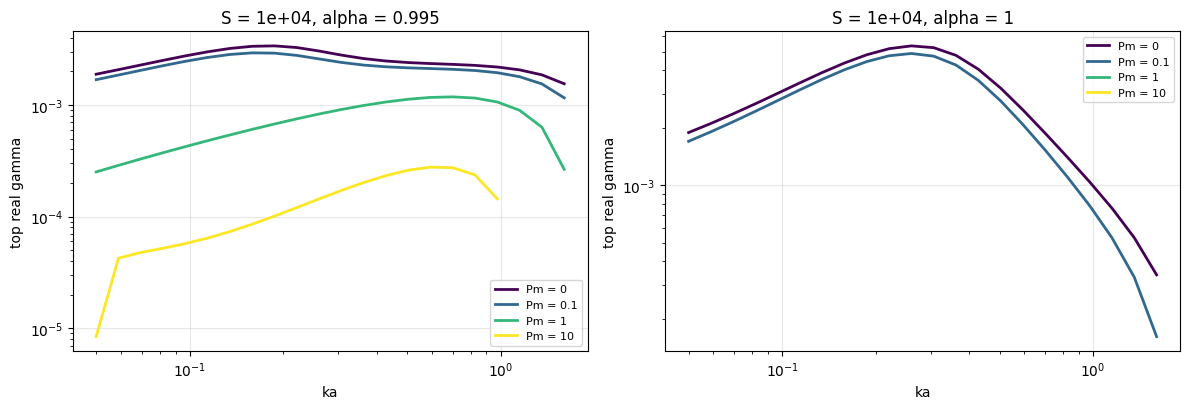

In [7]:
# gamma(k) with viscosity: the dense top over the scan grid at Pm = nu/eta (rung-2 box, coarse grid)
fig, axs = plt.subplots(1, len(L.PM_SCAN), figsize=(12, 4.2))
for ax, (S, al) in zip(np.atleast_1d(axs), L.PM_SCAN):
    for i, pm in enumerate(L.PM_SCAN_LIST):
        rows = PMS[(S, al, pm)]
        kas = sorted(rows)
        g = [L.top_real(rows[k]["values"]) for k in kas]
        c = SEQ(i/max(1, len(L.PM_SCAN_LIST) - 1))
        ax.plot(kas, np.where(np.array(g) > 0, g, np.nan), "-", lw=2, color=c, label=f"Pm = {pm:g}")
        mx = [(k, v) for k, v in L.scan_maxima(rows) if v > 0]
        cplx = [(k, complex(rows[k]["values"][0])) for k in kas
                if complex(rows[k]["values"][0]).real > 0 and L.top_real(rows[k]["values"]) == 0]
        print(f"S={S:.0e} alpha={al:g} Pm={pm:<4g}: real growing maxima " +
              (", ".join(f"ka {k:.4g} gamma {v:.4e}" for k, v in mx) or "NONE (no real growing mode at any ka)")
              + (f"; complex growing pairs at ka {', '.join(f'{k:g} ({z.real:.2e}{z.imag:+.2e}j)' for k, z in cplx)}" if cplx else ""))
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("ka"); ax.set_ylabel("top real gamma")
    ax.set_title(f"S = {S:.0e}, alpha = {al:g}"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Result (section 5).** The low-$k$ mode is a $\mathrm{Pm}\ll1$ phenomenon. At $\alpha=1$, $S=10^4$, $k^*=0.267$, $\gamma$ falls from $5.36\times10^{-3}$ ($\mathrm{Pm}=0$) to $3.88\times10^{-3}$ ($\mathrm{Pm}=0.3$), and at $\mathrm{Pm}=1$ the top eigenvalue is $-7.1\times10^{-6}$, as the theorem requires. At $\mathrm{Pm}=1$ there is no real growing mode at any $ka$ on the scan, and none at $\mathrm{Pm}=10$ either. At $\mathrm{Pm}=10$ a weak complex (overstable) pair grows at $ka\le0.07$ ($2.97\times10^{-5}$ at $ka=0.05$, where $kL_x=2.2$, so this is box-sensitive and not established here). At $\alpha=0.995$, $S=10^4$ the low-$k$ point drops by $5.2\times$ at $\mathrm{Pm}=1$ ($3.38\to0.654\times10^{-3}$), while the high-$k$ tearing maximum ($\alpha=0.99$, $ka=0.713$) drops by only $1.6\times$ ($3.36\to2.05\times10^{-3}$). In the full $\gamma(k)$ the low-$k$ maximum survives $\mathrm{Pm}=0.1$ (at $ka=0.16$, $2.92\times10^{-3}$) and is **gone at $\mathrm{Pm}=1$**: the only maximum is at $ka=0.70$ ($1.18\times10^{-3}$). The sensitivity at $\mathrm{Pm}=0$ gives the same picture: $(\eta/\gamma)\partial_\nu\gamma=-1.35$ on the low-$k$ branch at $S=10^4$ against $-0.84$ on the high-$k$ one.

### 6. Structure and energetics, both maxima at matched $(S,\alpha)$

At $S=10^4$ both maxima exist only in a narrow window around $\alpha_c=0.9916$ (section 7). Both are computed there, at $0.99$ (high only), $0.995$ (low only) and $1$. **Parity.** With flow there is no unitary parity: $u_0$ and $b_0$ are odd, so $x\to-x$ alone is not a symmetry. The equilibrium is invariant under the rotation $(x,y)\to(-x,-y)$, which on a ky block is $f(x)\to\overline{f(-x)}$. A real eigenvalue's eigenvector is invariant under it up to a phase (column `sym`: the residual after fixing $\psi(0)$ real), and that phase can always be absorbed (if $J\,v=\lambda v$ and $A$ is the antiunitary map, $J\,Av=\bar\lambda\,Av$; for a simple real $\lambda$, $Av=c\,v$ with $|c|=1$, and $v\to c^{1/2}v$ makes it invariant). So the parity label of the static problem becomes "Re $\psi$ even, Im $\psi$ odd" for *every* real mode, and the meaningful structural number is the reconnected flux $|\psi(0)|/\max|\psi|$. Budget columns are normalized by $2\gamma E$: $R=-\int U'\langle u_xu_y\rangle$, $M=\int U'\langle b_xb_y\rangle$ (stresses against the flow shear), $C=\int B'\langle u_yb_x-u_xb_y\rangle$ (work of the equilibrium current), $D_\eta$; Elsasser $T^\pm=-\tfrac12\int Z^{\pm\prime}\langle\delta z^\pm_y\delta z^\mp_x\rangle$, the cross-dissipation $X^-=-\tfrac{\nu-\eta}4\langle\omega^-\omega^+\rangle$ and $D^{--}$ (so that $2\gamma E^-=T^--D^{--}+X^-$). The closures are at $\le4\times10^{-10}$.

      S  alpha branch        k*    gamma*      psi0      E-/E   x_rms_E     width         R         M         C     D_eta        T+        T-        X-       D--   closure       sym
  1e+04 0.9916    low     0.175   0.00305     0.107   5.6e-05     0.731     0.387    -0.778      1.27     0.604    0.0935      1.09  0.000462 -0.000167  0.000239  3.23e-10  8.39e-10
  1e+04 0.9916   high     0.689   0.00305     0.289  2.87e-05     0.746     0.354      -9.3       9.8     0.666      0.16      1.16  0.000707 -0.000239   0.00044  3.67e-10  3.11e-11
  1e+04  0.995    low     0.179   0.00338    0.0715  4.32e-05     0.722     0.372    -0.261      0.76     0.582    0.0808      1.08  0.000202 -3.36e-05  0.000125  2.37e-10  3.41e-10
  1e+04   0.99   high     0.713   0.00336     0.299  3.99e-05     0.749     0.341     -8.24      8.73     0.671      0.16      1.16  0.000882 -0.000284  0.000558  3.61e-10  5.74e-11
  1e+04      1    low     0.267   0.00536    0.0184   3.7e-05     0.701     0.316      0.3

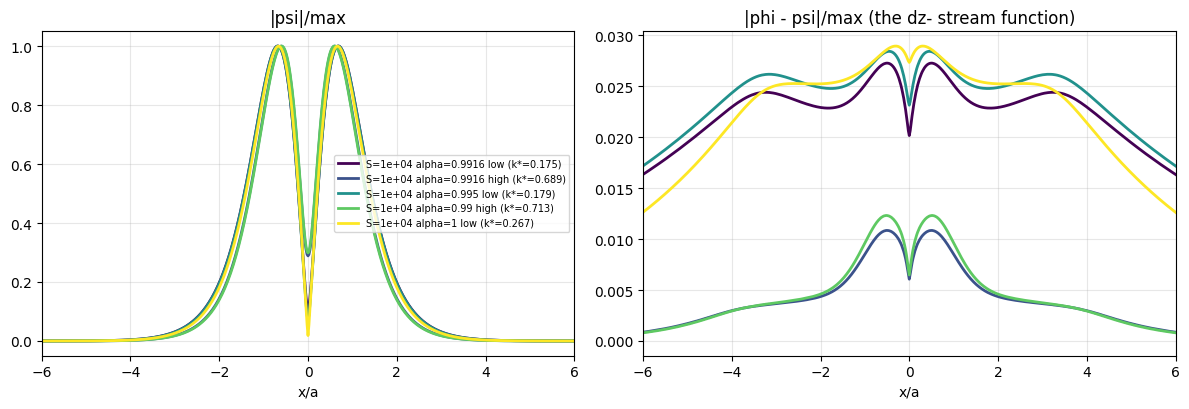

In [8]:
cols = ["k*", "gamma*", "psi0", "E-/E", "x_rms_E", "width", "R", "M", "C", "D_eta", "T+", "T-", "X-", "D--", "closure", "sym"]
print(f"{'S':>7s} {'alpha':>6s} {'branch':>6s} " + " ".join(f"{c:>9s}" for c in cols))
for (S, al, w), r in ST.items():
    rec = r["rec"]
    v = [r["kmax"], r["gmax"], float(rec["psi0"]), float(rec["em_frac"]), float(rec["x_rms_E"]), float(rec["width"]),
         float(rec["b_R"]), float(rec["b_M"]), float(rec["b_C"]), float(rec["b_Deta"]), float(rec["b_Tp"]),
         float(rec["b_Tm"]), float(rec["b_Xm"]), float(rec["b_Dmm"]), float(rec["closure"]), float(rec["sym_residual"])]
    print(f"{S:7.0e} {al:6g} {w:>6s} " + " ".join(f"{x:9.3g}" for x in v))
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
for i, ((S, al, w), r) in enumerate(ST.items()):
    rec = r["rec"]
    x = np.asarray(rec["xf"]); psi = np.asarray(rec["psif"]); phi = np.asarray(rec["phif"])
    s = max(np.abs(psi).max(), np.abs(phi).max())
    c = SEQ(i/max(1, len(ST) - 1))
    axs[0].plot(x, np.abs(psi)/s, "-", lw=2, color=c, label=f"S={S:.0e} alpha={al:g} {w} (k*={r['kmax']:.3f})")
    axs[1].plot(x, np.abs(phi - psi)/s, "-", lw=2, color=c)
for ax, t in zip(axs, ("|psi|/max", "|phi - psi|/max (the dz- stream function)")):
    ax.set_xlim(-6, 6); ax.set_xlabel("x/a"); ax.set_title(t); ax.grid(alpha=0.3)
axs[0].legend(fontsize=7); plt.tight_layout(); plt.show()

**Result (section 6).** Both maxima are real modes of the same symmetry class (`sym` at round-off), with similar inner-layer widths (0.32-0.39) and energy extents ($x_{rms}=0.70$-$0.75$). In both, about 0.6 of the net energy release is the work of the equilibrium current $C$ ($0.54$-$0.67$ of $2\gamma E$), with $D_\eta=0.05$-$0.16$. They differ in three ways:
* **Reconnected flux:** $|\psi(0)|/\max|\psi|=0.29$ (high) against $0.107$ (low) at the same $\alpha=0.9916$, then $0.072$ at $0.995$ and $0.018$ at $\alpha=1$.
* **Shear stresses:** the high-$k$ mode carries large, nearly cancelling Reynolds and Maxwell stresses ($R=-9.3$, $M=+9.8$ at $\alpha_c$). For the low-$k$ mode they are $O(1)$ ($-0.78$, $+1.27$), and at $\alpha=1$ both are positive ($+0.35$, $+0.16$).
* **What feeds $\delta z^-$:** at $\alpha=1$, $T^-\equiv0$, so $E^-$ is sustained only by the resistive cross term ($X^-=+5.0\times10^{-5}$ against $D^{--}=1.3\times10^{-5}$). For $\alpha<1$ the residual $Z^-$ shear ($T^-$) feeds both modes, and $X^-$ becomes a small sink.

The low-$k$ mode is the tearing mode that the Alfvénic flow almost freezes ($\delta z^+$-only, little flux reconnected), sustained by resistive symmetry breaking. It is not a separate shear-driven instability.

### 7. Where the low-$k$ maximum wins: $\alpha_c(S)$

$\alpha_c(S)$ is where the two local maxima of $\gamma(k)$ have equal height. It is the root in $u=\ln(1-\alpha^2)$ of $\ln(\gamma^*_{low}/\gamma^*_{high})$, with a bracketed Newton/secant/bisection; a branch whose maximum does not exist at that $\alpha$ counts as $\pm\infty$. Each maximum is a bounded Brent search in $\ln k$ on eigenvalues alone. The sensitivity route (Newton on $\partial_k\gamma$) is **refused by the harness** at $S\ge2\times10^4$ near $\alpha_c$ ($\kappa\approx2\times10^5$, so $\kappa\delta/\mathrm{gap}\approx1.0$-$1.9\times10^{-3}$ against $10^{-3}$). The refusals are respected; the eigenvalues themselves reproduce to $\le10^{-8}$ relative ($\sim2\times10^{-11}$ absolute) across shifts. Grids: rung-2 box, $n_x/4$ (shift-invert) for $S\le2\times10^4$; dense at $n_x=1024$ for $S\ge5\times10^4$, where every shift-invert shift fails in GMRES. Both maxima at the root are re-solved at the full rung-2 $n_x$ (dense: $2\times1024$). At $S=10^4$ the Newton/sensitivity route is an independent check. The **definition** (equal heights of the two local maxima) is the rung-2 "global maximum" picture made precise: the global $k_{max}$ jumps exactly where the two local maxima are equal, and where only one maximum exists (here $S\le2\times10^3$) there is no jump and no $\alpha_c$. All of this runs on the rung-2 box; the second cell below checks it against $L_x\times2$ (added in review).

      S     alpha_c  1-alpha_c^2    k*_lo    k*_hi      gamma* evals | grid check: gamma(nx_b)/gamma(nx) - 1 (lo, hi)
  1e+03   0.9509497  9.56946e-02  NO coexisting maxima in 9 evaluations: the maximum moves continuously (k* of the 'low' windows 0.332-0.499, of the 'high' windows 0.518-0.569); alpha here = where it crosses k = sqrt(k_lo k_hi) of the seeds
  2e+03   0.9710058  5.71477e-02  NO coexisting maxima in 9 evaluations: the maximum moves continuously (k* of the 'low' windows 0.288-0.382, of the 'high' windows 0.525-0.730); alpha here = where it crosses k = sqrt(k_lo k_hi) of the seeds
  5e+03   0.9857022  2.83912e-02   0.2379   0.6516  5.5461e-03     8 | -2.3e-11 +1.1e-11 (nx 1024 vs 4096)
  1e+04   0.9916001  1.67292e-02   0.1756   0.6895  3.0459e-03     4 | -1.5e-10 -2.5e-10 (nx 1024 vs 4096)
  2e+04   0.9950262  9.92288e-03   0.1324   0.7104  1.6807e-03     6 | -3.9e-10 -2.6e-09 (nx 2048 vs 8192)
  5e+04   0.9974774  5.03884e-03   0.0925   0.7226  7.7369e-04     6 | -4.9e-11

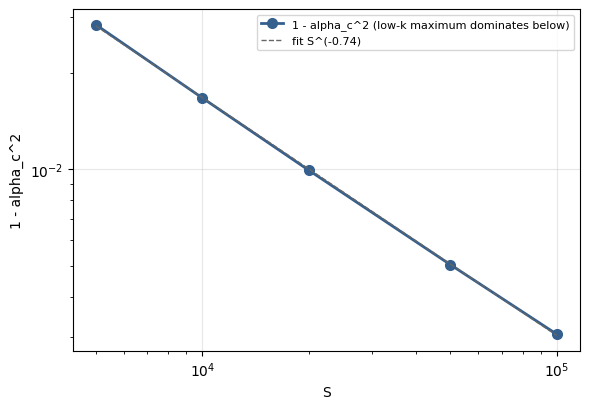

In [9]:
print(f"{'S':>7s} {'alpha_c':>11s} {'1-alpha_c^2':>12s} {'k*_lo':>8s} {'k*_hi':>8s} {'gamma*':>11s} {'evals':>5s} | grid check: gamma(nx_b)/gamma(nx) - 1 (lo, hi)")
Sv, qv = [], []
for S, r in BND.items():
    q = np.exp(r["u"])
    if not BOTH[S]:
        lo = [x["lo"]["kmax"] for x in r["rows"] if x["lo"] is not None]
        hi = [x["hi"]["kmax"] for x in r["rows"] if x["hi"] is not None]
        print(f"{S:7.0e} {r['alpha']:11.7f} {q:12.5e}  NO coexisting maxima in {len(r['rows'])} evaluations: the maximum "
              f"moves continuously (k* of the 'low' windows {min(lo):.3f}-{max(lo):.3f}, of the 'high' windows {min(hi):.3f}-{max(hi):.3f});"
              f" alpha here = where it crosses k = sqrt(k_lo k_hi) of the seeds")
        continue
    row = BOTH[S][-1]
    ch = BCHK[S]
    Sv.append(S); qv.append(q)
    print(f"{S:7.0e} {r['alpha']:11.7f} {q:12.5e} {row['lo']['kmax']:8.4f} {row['hi']['kmax']:8.4f} "
          f"{row['lo']['gmax']:11.4e} {len(r['rows']):5d} | {ch['lo'][0]/ch['lo'][1] - 1:+.1e} {ch['hi'][0]/ch['hi'][1] - 1:+.1e}"
          f" (nx {ch['nx_b']} vs {ch['nx']}{', dense' if L.boundary_nx(S)[2] else ''})")
for S, r in BNDN.items():
    print(f"Newton/sensitivity route at S = {S:.0e}: alpha_c = {r['alpha']:.7f}, 1 - alpha_c^2 = {np.exp(r['u']):.5e} "
          f"(Brent route {np.exp(BND[S]['u']) if S in BND else np.nan:.5e})")
Sv, qv = np.array(Sv), np.array(qv)
if len(Sv) > 1:
    loc = np.diff(np.log(qv))/np.diff(np.log(Sv))
    print("local slopes d ln(1 - alpha_c^2)/d ln S between neighbours: " + "  ".join(
        f"{Sv[i]:.0e}-{Sv[i+1]:.0e}: {loc[i]:+.3f}" for i in range(len(loc))))
    p = np.polyfit(np.log(Sv), np.log(qv), 1)
    print(f"power-law fit over S = {Sv[0]:.0e}-{Sv[-1]:.0e}: 1 - alpha_c^2 = {np.exp(p[1]):.3g} S^({p[0]:+.3f})")
    print("  extrapolated (NOT measured): " + ", ".join(f"S = {S:.0e}: {np.exp(p[1])*S**p[0]:.1e}" for S in (1e6, 1e8, 1e16)))
    fig, ax = plt.subplots(figsize=(6, 4.2))
    ax.loglog(Sv, qv, "o-", lw=2, ms=7, color=SEQ(0.3), label="1 - alpha_c^2 (low-k maximum dominates below)")
    ax.loglog(Sv, np.exp(p[1])*Sv**p[0], "--", lw=1, color="0.4", label=f"fit S^({p[0]:.2f})")
    ax.set_xlabel("S"); ax.set_ylabel("1 - alpha_c^2"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

In [10]:
# BOX check of alpha_c (added in review). The boundary runs on the rung-2 box, where the low-k maximum's
# image error ~ e^(-k*_lo Lx) grows with S (k*_lo Lx = 4.2 at S = 1e5). Both maxima of the last both-branch
# row, dense, on the rung-2 box (nx 1024) and on Lx x2 at the same dx (nx 2048); the root moved by the
# envelope theorem, u' = u_c - dgap/(d gap/du), the slope the secant of the two rows nearest the root
print(f"{'S':>7s} {'k*_lo Lx':>9s} {'lo: g(2Lx)/g(Lx)-1':>19s} {'hi: g(2Lx)/g(Lx)-1':>19s} {'dgap/du':>8s} "
      f"{'1-alpha_c^2':>12s} {'box-corrected':>14s} {'change':>9s}")
Sb, qb = [], []
for S, b in BBOX.items():
    q0, q1 = np.exp(BND[S]["u"]), np.exp(b["u"])
    Sb.append(S); qb.append(q1)
    print(f"{S:7.0e} {BOTH[S][-1]['lo']['kmax']*b['Lx']:9.2f} {b['lo'][1]/b['lo'][0] - 1:+19.2e} "
          f"{b['hi'][1]/b['hi'][0] - 1:+19.2e} {b['slope']:+8.3f} {q0:12.5e} {q1:14.5e} {q1/q0 - 1:+9.1e}")
Sb, qb = np.array(Sb), np.array(qb)
loc = np.diff(np.log(qb))/np.diff(np.log(Sb))
pb = np.polyfit(np.log(Sb), np.log(qb), 1)
print("box-corrected local slopes: " + "  ".join(f"{Sb[i]:.0e}-{Sb[i+1]:.0e}: {loc[i]:+.3f}" for i in range(len(loc))))
print(f"box-corrected power-law fit over S = {Sb[0]:.0e}-{Sb[-1]:.0e}: 1 - alpha_c^2 = {np.exp(pb[1]):.3g} S^({pb[0]:+.3f})")
print("  extrapolated (NOT measured): " + ", ".join(f"S = {S:.0e}: {np.exp(pb[1])*S**pb[0]:.1e}" for S in (1e6, 1e8, 1e16)))
q2e4 = np.exp(BBOX[2e4]["u"])
print(f"alpha = 0.995 at S = 2e4: 1 - alpha^2 = {1 - 0.995**2:.5e} > 1 - alpha_c^2 = {q2e4:.5e}: the HIGH-k maximum is the global one")


      S  k*_lo Lx  lo: g(2Lx)/g(Lx)-1  hi: g(2Lx)/g(Lx)-1  dgap/du  1-alpha_c^2  box-corrected    change
  5e+03      9.28           -4.20e-05           +1.27e-11   -0.475  2.83912e-02    2.83887e-02  -8.8e-05
  1e+04      7.55           -3.18e-04           -5.18e-12   -0.692  1.67292e-02    1.67215e-02  -4.6e-04
  2e+04      6.29           -1.33e-03           +1.66e-12   -0.783  9.92288e-03    9.90606e-03  -1.7e-03
  5e+04      5.00           -5.44e-03           -3.11e-12   -0.959  5.03884e-03    5.01028e-03  -5.7e-03
  1e+05      4.22           -1.25e-02           -2.56e-11   -1.049  3.04810e-03    3.01170e-03  -1.2e-02
box-corrected local slopes: 5e+03-1e+04: -0.764  1e+04-2e+04: -0.755  2e+04-5e+04: -0.744  5e+04-1e+05: -0.734
box-corrected power-law fit over S = 5e+03-1e+05: 1 - alpha_c^2 = 16.6 S^(-0.749)
  extrapolated (NOT measured): S = 1e+06: 5.3e-04, S = 1e+08: 1.7e-05, S = 1e+16: 1.7e-11
alpha = 0.995 at S = 2e4: 1 - alpha^2 = 9.97500e-03 > 1 - alpha_c^2 = 9.90606e-03: the 

**Result (section 7).** For $S\ge5\times10^3$ the switch is a jump between two coexisting maxima, and $1-\alpha_c^2$ falls from $2.839\times10^{-2}$ ($S=5\times10^3$, $\alpha_c=0.98570$) through $1.673\times10^{-2}$ ($10^4$), $9.923\times10^{-3}$ ($2\times10^4$) and $5.039\times10^{-3}$ ($5\times10^4$) to $3.048\times10^{-3}$ ($10^5$, $\alpha_c=0.998475$). The local slopes $d\ln(1-\alpha_c^2)/d\ln S$ are $-0.763$, $-0.754$, $-0.740$, $-0.725$, and the fit over $5\times10^3$-$10^5$ gives $1-\alpha_c^2=16\,S^{-0.745}$. The slope is still flattening, so the asymptotic exponent is not settled by this range. The two maxima separate: $k^*_{low}=0.238\to0.071$, $k^*_{high}=0.65\to0.72$. The grid checks move $\gamma$ by $\le2.6\times10^{-9}$. At $S=10^4$ the sensitivity route gives $1.67282\times10^{-2}$ against the eigenvalue-only $1.67292\times10^{-2}$. At $S=10^3$ and $2\times10^3$ the two maxima never coexist within the window resolution: the maximum migrates continuously (the flat top of section 2), and the listed $\alpha$ only marks where it crosses mid-$k$ ($1-\alpha^2\approx0.096$ and $0.057$).

**Box check (added in review).** The box, not the grid, is the larger error here. Doubling $L_x$ lowers the low-$k$ $\gamma^*$ by $4.2\times10^{-5}$, $3.2\times10^{-4}$, $1.3\times10^{-3}$, $5.4\times10^{-3}$ and $1.25\times10^{-2}$ at $S=5\times10^3$-$10^5$ ($k^*_{low}L_x$ falls from $9.3$ to $4.2$), while the high-$k$ one moves by $\le3\times10^{-11}$. The box-corrected $1-\alpha_c^2$ is lower by $0.01\%$-$1.2\%$ ($3.012\times10^{-3}$ at $10^5$), the fit becomes $1-\alpha_c^2=16.6\,S^{-0.749}$, and the local slopes $-0.764$, $-0.755$, $-0.744$, $-0.734$. So the box shifts the exponent by $0.004$ and leaves the conclusions unchanged. (An independent check in review, with a `Parameters` built directly at each $L_y=2\pi/k$ and numpy's dense eig, reproduces $1-\alpha_c^2$ at $S=5\times10^4$ and $10^5$ on the rung-2 box to all five printed digits.) One consequence for rung 2: at $S=2\times10^4$, $\alpha=0.995$ lies just below $\alpha_c$, so the high-$k$ maximum is the global one there (by $0.4\%$ in $\gamma^*$ on the rung-2 box: $1.6797$ against $1.6867\times10^{-3}$, review check by the independent dense route). `tearing-kmax.ipynb` section 4's "$\alpha=0.995$: low-$k$ for $S\le2\times10^4$" followed the low-$k$ *local* maximum at that $S$.

**So the window in which the low-$k$ maximum dominates closes toward $\alpha=1$, roughly like $S^{-3/4}$ over $S=5\times10^3$-$10^5$:** at $S=10^5$ it needs $1-\alpha^2<3\times10^{-3}$. Extrapolating the fit, which is an extrapolation over 3 to 11 decades with a slope that is still drifting and not a measurement, gives $1-\alpha_c^2\sim2\times10^{-5}$ at $S=10^8$ and $\sim2\times10^{-11}$ at $S=10^{16}$, the paper's range. If that trend holds, the mode is irrelevant there for any realistic $\alpha$. With $\mathrm{Pm}\gtrsim1$ the low-$k$ maximum is absent at the one point tested ($S=10^4$, $\alpha=0.995$, section 5).

### 8. The Julia reference npz

`tests/data/shear_tearing_reference.npz` (rung 1b-ref) covers $\alpha\le0.95$, $ka=0.1$-$1$, $S=10^3$-$10^5$. The only place it overlaps the low-$k$ phenomenon is $S=10^3$, $\alpha=0.95$, the flat top where the two humps merge.

In [11]:
ref = np.load(os.path.join("..", "tests", "data", "shear_tearing_reference.npz"))
print("Julia reference npz coverage (whichf = 2): alpha in", sorted(set(ref["alpha"][ref["whichf"] == 2].tolist())),
      ", ka in", sorted(set(ref["ka"][ref["whichf"] == 2].tolist())), ", S in", sorted(set(ref["S"].tolist())))
for (S, ka, al), top in REF.items():
    i = [j for j in range(len(ref["S"])) if ref["whichf"][j] == 2 and ref["S"][j] == S and ref["ka"][j] == ka
         and ref["alpha"][j] == al][0]
    g = L.top_real(top["values"]); gr = complex(ref["gamma"][i]).real
    print(f"  S={S:.0e} ka={ka:<4g} alpha={al}: taranis (rung-2 box, nx {min(L.NX_DENSE, L.box(S)[1])}) {g:.6e}   "
          f"Julia {gr:.6e} (relative error bar {float(ref['gamma_err'][i]):.1e})   diff {g/gr - 1:+.1e}   (k Lx = {ka*L.box(S)[0]:.1f})")

Julia reference npz coverage (whichf = 2): alpha in [0.0, 0.3, 0.6, 0.8, 0.95] , ka in [0.1, 0.2, 0.3, 0.5, 0.7, 1.0] , S in [1000.0, 10000.0, 100000.0]
  S=1e+03 ka=0.1  alpha=0.95: taranis (rung-2 box, nx 1024) 1.256544e-02   Julia 1.225121e-02 (relative error bar 5.2e-04)   diff +2.6e-02   (k Lx = 3.1)
  S=1e+03 ka=0.2  alpha=0.95: taranis (rung-2 box, nx 1024) 1.856481e-02   Julia 1.856089e-02 (relative error bar 9.3e-04)   diff +2.1e-04   (k Lx = 6.2)
  S=1e+03 ka=0.3  alpha=0.95: taranis (rung-2 box, nx 1024) 2.130744e-02   Julia 2.132090e-02 (relative error bar 6.6e-04)   diff -6.3e-04   (k Lx = 9.4)
  S=1e+03 ka=0.5  alpha=0.95: taranis (rung-2 box, nx 1024) 2.227716e-02   Julia 2.227996e-02 (relative error bar 1.3e-04)   diff -1.3e-04   (k Lx = 15.6)
  S=1e+03 ka=0.7  alpha=0.95: taranis (rung-2 box, nx 1024) 2.214159e-02   Julia 2.214157e-02 (relative error bar 3.9e-05)   diff +6.4e-07   (k Lx = 21.9)
  S=1e+03 ka=1    alpha=0.95: taranis (rung-2 box, nx 1024) 2.099700e-02   

**Result (section 8).** The reference reproduces the flat top: Julia's $\gamma$ at $ka=0.3$, $0.5$, $0.7$ is $2.1321$, $2.2280$, $2.2142\times10^{-2}$, against taranis' $2.1307$, $2.2277$, $2.2142\times10^{-2}$. The differences ($-6.3\times10^{-4}$, $-1.257\times10^{-4}$, $6\times10^{-7}$) are within, or at, the reference's own relative error bars ($6.6\times10^{-4}$, $1.252\times10^{-4}$, $3.9\times10^{-5}$): at $ka=0.5$ the difference exceeds the bar by $0.4\%$ of it. The exception is $ka=0.1$ ($+2.6\%$), where the rung-2 box has $kL_x=3.1$, the image error of section 1. The npz does not reach $\alpha>0.95$, so it contains no point where the low-$k$ maximum is distinct. The independent Julia check of the branch itself is section 1: open boundary, $\le1.3\times10^{-6}$ at $\alpha=0.995$ and $8\times10^{-7}$ at $\alpha=1$.

### 9. Summary

* **Not an artifact.** Converged in $n_x$ ($<10^{-10}$) and $L_x$ ($2\times10^{-7}$ at $L_x\times2$ vs $\times4$), and reproduced by the Julia eigencode with an open boundary ($\le1.3\times10^{-6}$). The rung-2 box carries a $5$-$8\times10^{-4}$ image error on this branch at $S=10^4$. The error grows with $S$ ($1.25\%$ at $10^5$) and moves $\alpha_c$ by $\le1.2\%$ in $1-\alpha_c^2$ (section 7).
* **What it is.** The low-$k$ maximum is the $\alpha\to1$ end of the single real tearing branch. At $\alpha=1$ ($Z^-=0$) no eigenmode grows when $\nu=\eta>0$. This is a modal statement: $\|\delta z^-\|$ decays monotonically, but $\delta z^+$ and the total energy can grow transiently. With $\nu=0$ a $\Delta'$-driven resistive mode remains (cut off at $ka=\sqrt5$), with $\gamma^*\propto S^{-0.66}$, $k^*\propto S^{-0.17}$, little reconnected flux ($|\psi(0)|/\max|\psi|\le0.054$) and almost no $\delta z^-$ ($E^-/E\le6\times10^{-4}$). Its $\delta z^-$ is sustained by the resistive cross-dissipation $\tfrac{\nu-\eta}2\nabla^2\delta z^+$. For $\alpha>1$ the same real branch is the ideal Kelvin-Helmholtz instability ($\gamma$ independent of $S$). For $\alpha<1$ it survives as the low-$k$ hump, while the paper's high-$k$ shear-modified tearing maximum vanishes as $(1-\alpha^2)^{0.59}$.
* **Viscosity.** It needs $\mathrm{Pm}\ll1$. At $\mathrm{Pm}=1$ it is absent at $\alpha=1$ (the statement of section 4), and the low-$k$ maximum is gone at $S=10^4$, $\alpha=0.995$, while the high-$k$ maximum loses only a factor 1.6. It survives $\mathrm{Pm}=0.1$. This is one $(S,\alpha)$ point; the $\mathrm{Pm}$ threshold is not mapped.
* **Where it matters.** $1-\alpha_c^2=16\,S^{-0.745}$ for $S=5\times10^3$-$10^5$ on the rung-2 box ($16.6\,S^{-0.749}$ box-corrected; local slope flattening from $-0.76$ to $-0.73$); below $5\times10^3$ the maximum migrates continuously. The window closes toward $\alpha=1$ as $S$ grows, so, if the measured trend continues, the paper's high-$k$ scalings hold at large $S$ except in an ever thinner, low-$\mathrm{Pm}$ sliver near $\alpha=1$. At $S=2\times10^4$, $\alpha=0.995$ the global maximum is the high-$k$ one (by $0.4\%$, review check), which corrects rung 2's branch label there.

**Not settled here:** the asymptotic exponents (the $\alpha=1$ exponents $-0.66$/$-0.17$ have no derived theory here; the $\alpha_c$ slope is still drifting); the weak complex pair at $\alpha=1$, $\mathrm{Pm}=10$, $ka\le0.07$ (box-sensitive); $\alpha_c$ at $S>10^5$ (dense $n_x=1024$ will not hold there, and the rung-2 box would need enlarging); the $\mathrm{Pm}$-dependence of $\alpha_c$ (rung 2b viscosity notebook).